In [1]:
import numpy as np
import pandas as pd
import pickle
import gzip
import matplotlib.pyplot as plt

# Librerie per Motif e Shapelets
import stumpy
from aeon.classification.shapelet_based import RDSTClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, RocCurveDisplay

# Analisi Motifs e Shapelets (Denoised, Unstandardized)
Seguendo le direttive architetturali e i feedback ricevuti, in questo notebook analizziamo i dati **denoised** ma **non standardizzati** a livello di istanza, al fine di preservare l'intensità assoluta del movimento (energia e varianza reali dei pazienti).

In [2]:
# Caricamento del dataset denoised puro (media mobile a 5 step, nessuna normalizzazione Z-score)
with gzip.open("ts_motifs_ready.pkl.gz", "rb") as f:
    ts_denoised = pickle.load(f)

print(f"Caricate {len(ts_denoised)} Time Series denoised.")

Caricate 4437 Time Series denoised.


## Preparazione Array per i Modelli
Estraiamo la feature `enmo` (intensità del movimento) e dividiamo in Train e Test set in modo stratificato rispetto al target `sii_binary`.

In [3]:
# Usiamo la variabile ENMO come feature principale.
X = []
for df in ts_denoised:
    arr = df['enmo'].values
    # Fix per l'errore di aeon sulle time series con varianza nulla (es. bambino perfettamente immobile)
    if np.std(arr) <= 1e-7:
        arr = arr + np.random.normal(0, 1e-5, size=len(arr))
    X.append(arr)

# Estraiamo l'label globale per ogni soggetto
y = np.array([df['sii_binary'].iloc[0] for df in ts_denoised])

# Splittiamo in Train e Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=222, stratify=y)

print(f"Numero di serie in Train: {len(X_train)}")
print(f"Numero di serie in Test: {len(X_test)}")

Numero di serie in Train: 3105
Numero di serie in Test: 1332


## Fase 1: Motifs e Discords (Matrix Profile)
Usiamo i medoidi estratti precedentemente nel modulo di clustering per osservare visivamente i pattern più frequenti e le anomalie.

In [4]:
# --- CONFIGURAZIONE GLOBALE ---
m = 8                          # Window size (es. 16 campionamenti = 8 ore se step=30min)
target_features = ['enmo'] # 'anglez'        # Variabile su cui calcolare il Matrix Profile (es. 'enmo', 'anglez', 'light')

k_clusters_motif = 3            # Numero di cluster desiderati per l'analisi dei Motif DTW
k_clusters_multi = 4            # Numero di cluster per l'analisi Multivariata Dataset-wise

top_k_motifs = 2                # Quanti Motif estrarre per ogni time series
top_k_discords = 2              # Quanti Discord estrarre per ogni time series

n_shapelets = 3                 # Numero di Shapelet da estrarre

# Variabile di supporto per stampare le etichette di tempo automaticamente
h_str = f"{m/2:g} ore"
print("Parametri configurati correttamente!")


Parametri configurati correttamente!



ANALISI SULLA FEATURE: enmo



OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.



--- ANALISI DEL MEDOIDE 1583 (enmo) ---
Top-2 Motifs found. Example Top-1 at indices: [np.int64(83), 161]
   -> This means that the 4 ore blocks starting at these indices are nearly identical (routines).
Top-2 Discords found at indices: [169 189]
   -> The 4 ore windows starting at these steps are the most unique and anomalous in the series.



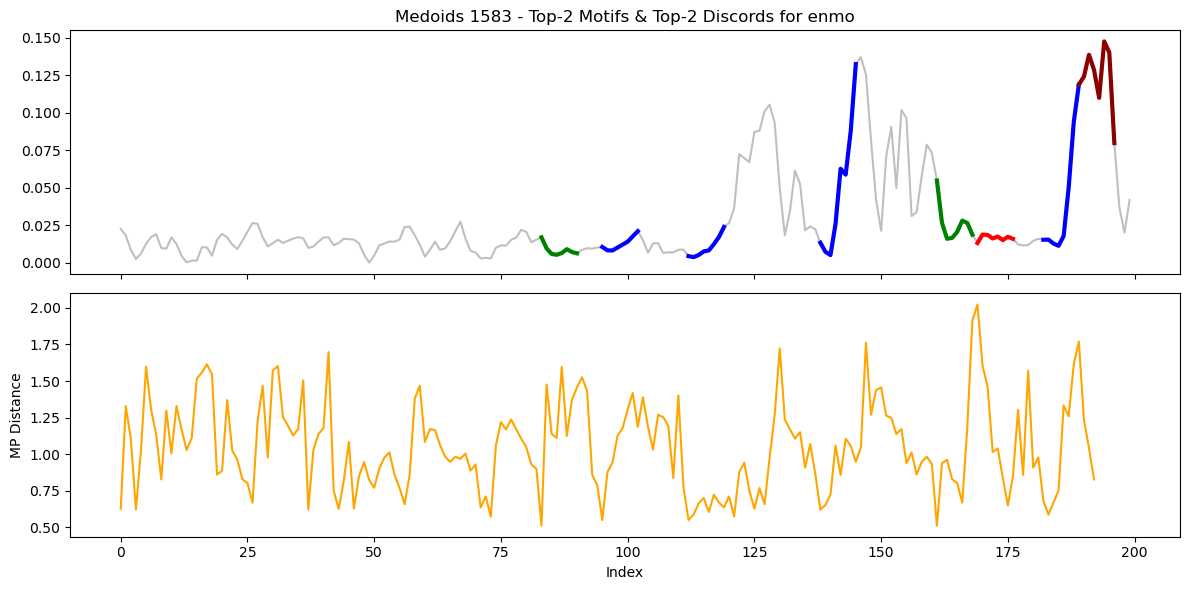


--- ANALISI DEL MEDOIDE 1606 (enmo) ---
Top-2 Motifs found. Example Top-1 at indices: [np.int64(34), 112]
   -> This means that the 4 ore blocks starting at these indices are nearly identical (routines).
Top-2 Discords found at indices: [188 183]
   -> The 4 ore windows starting at these steps are the most unique and anomalous in the series.



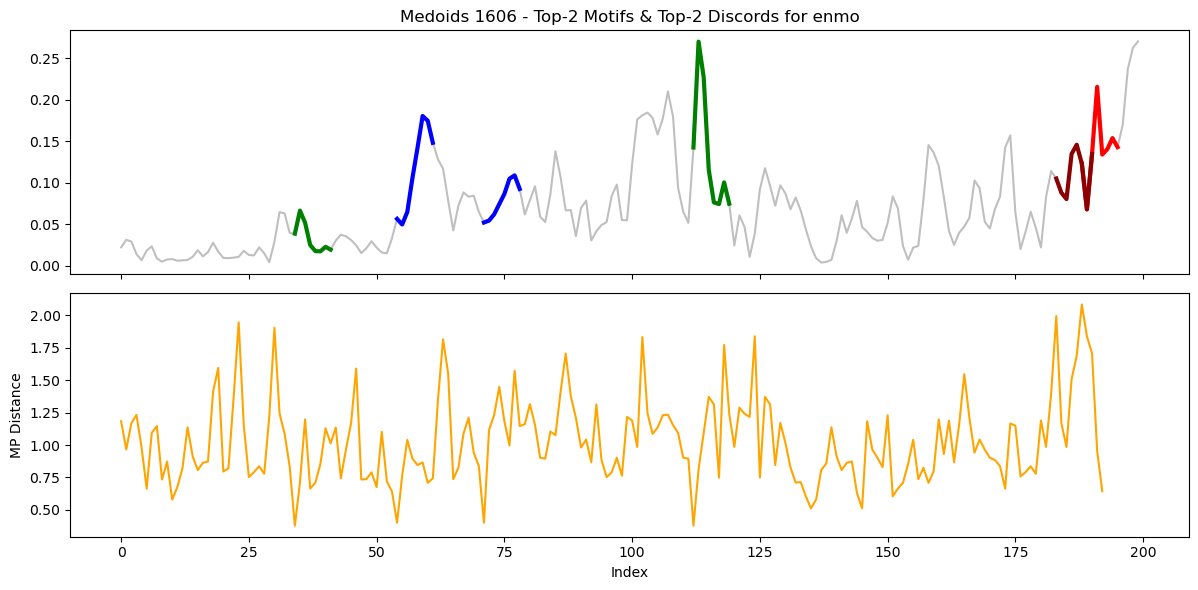


--- ANALISI DEL MEDOIDE 1248 (enmo) ---
Top-2 Motifs found. Example Top-1 at indices: [np.int64(112), 131]
   -> This means that the 4 ore blocks starting at these indices are nearly identical (routines).
Top-2 Discords found at indices: [34 29]
   -> The 4 ore windows starting at these steps are the most unique and anomalous in the series.



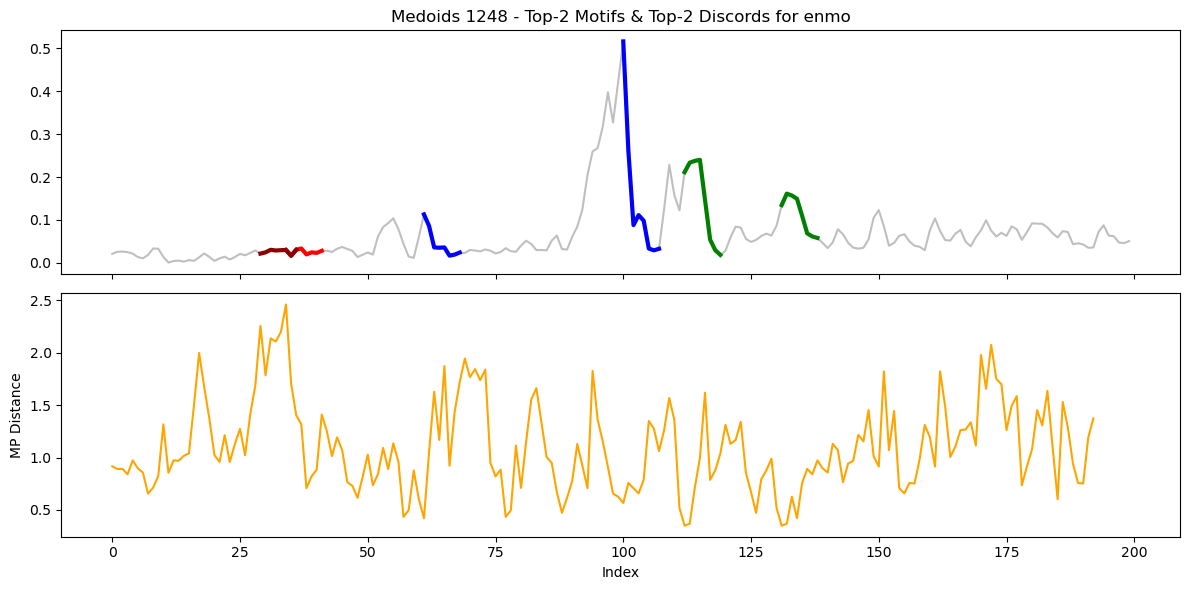

In [ ]:
from matrixprofile import motifs
from matrixprofile.discords import discords

medoid_idx = [1583, 1606, 1248]
medoids = [ts_denoised[i] for i in medoid_idx]

for target_feature in target_features:
    print(f"\n{'='*50}\nANALISI SULLA FEATURE: {target_feature}\n{'='*50}\n")
    
    for i, ts_df in enumerate(medoids):
        ts_medoide = ts_df[target_feature].values.astype(np.float64)

        # Calcoliamo il MP con stumpy per avere la matrice base
        mp_full = stumpy.stump(ts_medoide, m)
        mp_dist = mp_full[:, 0].astype(np.float64)
        mpi = mp_full[:, 1].astype(np.int64)

        # Estrattore Motifs tramite matrixprofile-ts come richiesto
        mo, mod = motifs.motifs(ts_medoide, (mp_dist, mpi), max_motifs=top_k_motifs)
        
        # Estrattore Discords tramite matrixprofile-ts come richiesto
        anoms = discords(mp_dist, ex_zone=int(m/2), k=top_k_discords)

        print(f"\n--- ANALISI DEL MEDOIDE {medoid_idx[i]} ({target_feature}) ---")
        if len(mo) > 0:
            print(f"Top-{len(mo)} Motifs found. Example Top-1 at indices: {mo[0]}")
            print(f"   -> This means that the {h_str} blocks starting at these indices are nearly identical (routines).")
        
        if len(anoms) > 0:
            print(f"Top-{len(anoms)} Discords found at indices: {anoms}")
            print(f"   -> The {h_str} windows starting at these steps are the most unique and anomalous in the series.\n")

        # Configurazione struttura subplots originale: 1 per le TS con Motifs/Discords, 1 per il Matrix Profile
        fig, axs = plt.subplots(2, 1, sharex=True, figsize=(12, 6))
        
        # PLOT DEI MOTIFS E DISCORDS INSIEME
        axs[0].plot(ts_medoide, label=f"Time Series ('{target_feature}')", color='gray', alpha=0.5)
        axs[0].set_title(f"Medoids {medoid_idx[i]} - Top-{top_k_motifs} Motifs & Top-{top_k_discords} Discords for {target_feature}")
        
        # Plot Motifs
        colors_mo = ['g', 'b', 'black', 'm', 'y'][:max(1, len(mo))]

        for motif_group, d, c in zip(mo, mod, colors_mo):
            for idx in motif_group:
                m_shape = ts_medoide[idx : idx + m]
                axs[0].plot(range(idx, idx + m), m_shape, color=c, lw=3)
                
        # Plot Discords (in rosso)
        colors_anom = ['r', 'darkred', 'salmon', 'orange', 'k'][:max(1, len(anoms))]
        for a, c in zip(anoms, colors_anom):
            a_shape = ts_medoide[a : a + m]
            axs[0].plot(range(a, a + m), a_shape, color=c, lw=3)
            
        #axs[0].legend(loc='upper right')

        # PLOT DELLA MATRIX PROFILE DISTANCE (Valli e Picchi)
        axs[1].plot(mp_dist, color='orange')
        axs[1].set_ylabel('MP Distance')
        axs[1].set_xlabel('Index')
        
        plt.tight_layout()
        plt.show()


In [ ]:
from matrixprofile import motifs
from matrixprofile.discords import discords

medoid_idx = [1583, 1606, 1248]
medoids = [ts_denoised[i] for i in medoid_idx]

for target_feature in target_features:
    print(f"\n{'='*50}\nANALISI SULLA FEATURE: {target_feature}\n{'='*50}\n")
    
    for i, ts_df in enumerate(medoids):
        ts_medoide = ts_df[target_feature].values.astype(np.float64)

        # Calcoliamo il MP con stumpy per avere la matrice base
        mp_full = stumpy.stump(ts_medoide, 4)
        mp_dist = mp_full[:, 0].astype(np.float64)
        mpi = mp_full[:, 1].astype(np.int64)

        # Estrattore Motifs tramite matrixprofile-ts come richiesto
        mo, mod = motifs.motifs(ts_medoide, (mp_dist, mpi), max_motifs=top_k_motifs)
        
        # Estrattore Discords tramite matrixprofile-ts come richiesto
        anoms = discords(mp_dist, ex_zone=int(m/2), k=top_k_discords)

        print(f"\n--- ANALISI DEL MEDOIDE {medoid_idx[i]} ({target_feature}) ---")
        if len(mo) > 0:
            print(f"Top-{len(mo)} Motifs found. Example Top-1 at indices: {mo[0]}")
            print(f"   -> This means that the {h_str} blocks starting at these indices are nearly identical (routines).")
        
        if len(anoms) > 0:
            print(f"Top-{len(anoms)} Discords found at indices: {anoms}")
            print(f"   -> The {h_str} windows starting at these steps are the most unique and anomalous in the series.\n")

        # Configurazione struttura subplots originale: 1 per le TS con Motifs/Discords, 1 per il Matrix Profile
        fig, axs = plt.subplots(2, 1, sharex=True, figsize=(12, 6))
        
        # PLOT DEI MOTIFS E DISCORDS INSIEME
        axs[0].plot(ts_medoide, label=f"Time Series ('{target_feature}')", color='gray', alpha=0.5)
        axs[0].set_title(f"Medoids {medoid_idx[i]} - Top-{top_k_motifs} Motifs & Top-{top_k_discords} Discords for {target_feature}")
        
        # Plot Motifs
        colors_mo = ['g', 'b', 'black', 'm', 'y'][:max(1, len(mo))]

        for motif_group, d, c in zip(mo, mod, colors_mo):
            for idx in motif_group:
                m_shape = ts_medoide[idx : idx + m]
                axs[0].plot(range(idx, idx + m), m_shape, color=c, lw=3)
                
        # Plot Discords (in rosso)
        colors_anom = ['r', 'darkred', 'salmon', 'orange', 'k'][:max(1, len(anoms))]
        for a, c in zip(anoms, colors_anom):
            a_shape = ts_medoide[a : a + m]
            axs[0].plot(range(a, a + m), a_shape, color=c, lw=3)
            
        #axs[0].legend(loc='upper right')

        # PLOT DELLA MATRIX PROFILE DISTANCE (Valli e Picchi)
        axs[1].plot(mp_dist, color='orange')
        axs[1].set_ylabel('MP Distance')
        axs[1].set_xlabel('Index')
        
        plt.tight_layout()
        plt.show()


## Fase 2: Estrazione Shapelets (RDSTClassifier)
Ora addestriamo l'RDSTClassifier per l'estrazione degli shapelets globali che massimizzano la separabilità tra Alto e Basso Rischio.


Inizio tuning con RandomizedSearchCV (10 iterazioni, 3-fold CV)...
Fitting 3 folds for each of 10 candidates, totalling 30 fits
[CV] END estimator__criterion=entropy, estimator__max_depth=None, estimator__min_samples_leaf=4, estimator__min_samples_split=20, max_shapelets=3000, shapelet_lengths=[10, 11, 15]; total time=  10.3s
[CV] END estimator__criterion=entropy, estimator__max_depth=None, estimator__min_samples_leaf=4, estimator__min_samples_split=20, max_shapelets=3000, shapelet_lengths=[10, 11, 15]; total time=  11.2s
[CV] END estimator__criterion=entropy, estimator__max_depth=None, estimator__min_samples_leaf=4, estimator__min_samples_split=20, max_shapelets=3000, shapelet_lengths=[10, 11, 15]; total time=  12.1s
[CV] END estimator__criterion=gini, estimator__max_depth=5, estimator__min_samples_leaf=2, estimator__min_samples_split=2, max_shapelets=3000, shapelet_lengths=[10, 11, 15]; total time=   5.8s
[CV] END estimator__criterion=gini, estimator__max_depth=5, estimator__min_sam

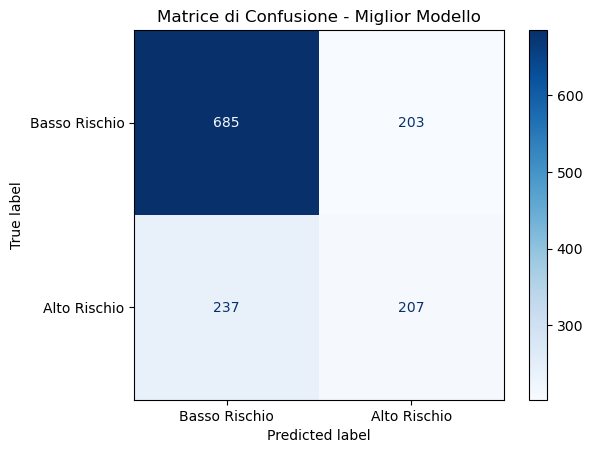

In [6]:
from sklearn.model_selection import RandomizedSearchCV, train_test_split

dt = DecisionTreeClassifier(random_state=222, class_weight='balanced')

# RDSTClassifier con n_jobs=-1 per sfruttare tutti i core della CPU nell'estrazione
clf = RDSTClassifier(
    estimator=dt, 
    random_state=222, 
    use_prime_dilations=True, 
    n_jobs=-1
)

# 3. Definizione dello Spazio dei Parametri (Parameter Grid)
# Usiamo la notazione "estimator__" per modificare i parametri del Decision Tree interno
param_dist = {
    # Parametri RDST
    'max_shapelets': [3000], #[1000, 2000, 3000],
    'shapelet_lengths': [[8, 12, 16], [10, 11, 15]],
    
    # Parametri Decision Tree (estimator)
    'estimator__max_depth': [3, 5, 7, None],
    'estimator__min_samples_split': [2, 5, 10, 20],
    'estimator__min_samples_leaf': [1, 2, 4, 8],
    'estimator__criterion': ['gini', 'entropy']
}

# 4. Configurazione della Ricerca Casuale (RandomizedSearchCV)
# Impostiamo n_jobs=1 sul search esterno per evitare conflitti con il n_jobs=-1 di RDST (evita memory leaks)
random_search = RandomizedSearchCV(
    estimator=clf,
    param_distributions=param_dist,
    n_iter=10,            # Numero di combinazioni casuali da testare (veloce ma robusto)
    cv=3,                 # 3-Fold Cross-Validation
    scoring='f1_macro',   # Ottimizziamo su F1-Macro per bilanciare le classi
    random_state=222,
    n_jobs=1,             
    verbose=2
)

# 5. Esecuzione del Tuning
print("\nInizio tuning con RandomizedSearchCV (10 iterazioni, 3-fold CV)...")
random_search.fit(X_train, y_train)

# 6. Analisi dei Risultati
print("\n" + "="*50)
print("MIGLIORI PARAMETRI TROVATI:")
print("="*50)
for param, value in random_search.best_params_.items():
    print(f" - {param}: {value}")
print(f"Miglior F1-Score in CV: {random_search.best_score_:.4f}")
print("="*50 + "\n")

# Valutazione sul Test Set con il miglior modello
best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test)

print("=== REPORT DI CLASSIFICAZIONE (TEST SET) ===")
print(classification_report(y_test, y_pred, target_names=["Basso Rischio", "Alto Rischio"]))

# Plot della Matrice di Confusione
ConfusionMatrixDisplay.from_estimator(
    best_model, X_test, y_test, 
    display_labels=["Basso Rischio", "Alto Rischio"], 
    cmap='Blues'
)
plt.title("Matrice di Confusione - Miglior Modello")
plt.show()

Inizio Addestramento con RDSTClassifier + DecisionTree...
=== REPORT DI CLASSIFICAZIONE ===
              precision    recall  f1-score   support

       sii=0       0.71      0.90      0.79       888
       sii=1       0.56      0.26      0.36       444

    accuracy                           0.68      1332
   macro avg       0.63      0.58      0.57      1332
weighted avg       0.66      0.68      0.65      1332



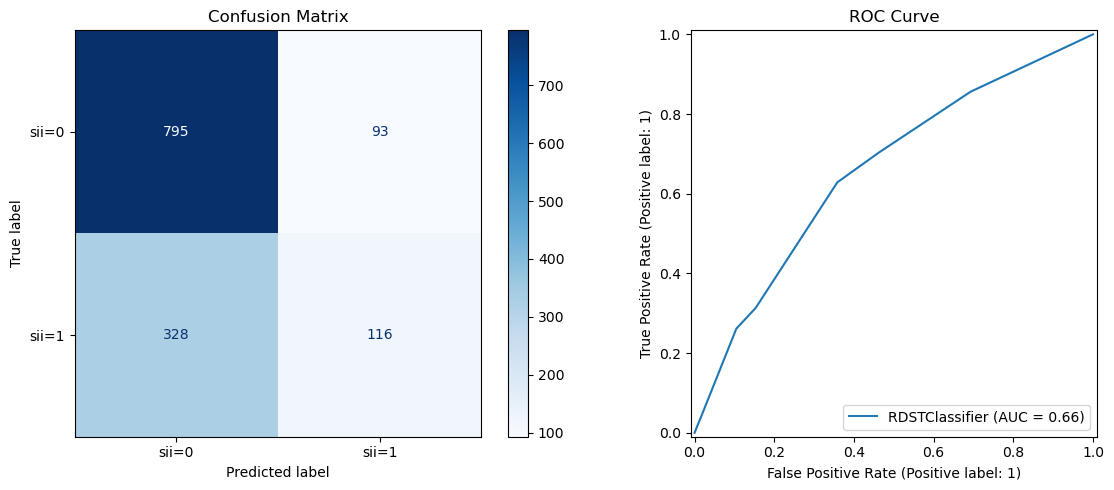

In [7]:
print("Inizio Addestramento con RDSTClassifier + DecisionTree...")
#dt = DecisionTreeClassifier(max_depth=3, random_state=222)
dt = DecisionTreeClassifier(min_samples_split= 5,min_samples_leaf= 8,max_depth= 3, criterion= 'entropy', random_state=222)
clf = RDSTClassifier(
    max_shapelets=10000, 
    estimator=dt, 
    random_state=222, 
    n_jobs=-1, 
    shapelet_lengths=[10,11,15], 
    use_prime_dilations=True, 
    save_transformed_data=True
    #class_weight='balanced_subsample'
)

clf.fit(X_train, y_train)

# Valutazione
y_pred = clf.predict(X_test)
print("=== REPORT DI CLASSIFICAZIONE ===")
print(classification_report(y_test, y_pred, target_names=["sii=0", "sii=1"]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_estimator(clf, X_test, y_test, display_labels=["sii=0", "sii=1"], cmap="Blues", ax=ax1)
ax1.set_title("Confusion Matrix")
RocCurveDisplay.from_estimator(clf, X_test, y_test, ax=ax2)
ax2.set_title("ROC Curve")
plt.tight_layout()
plt.show()

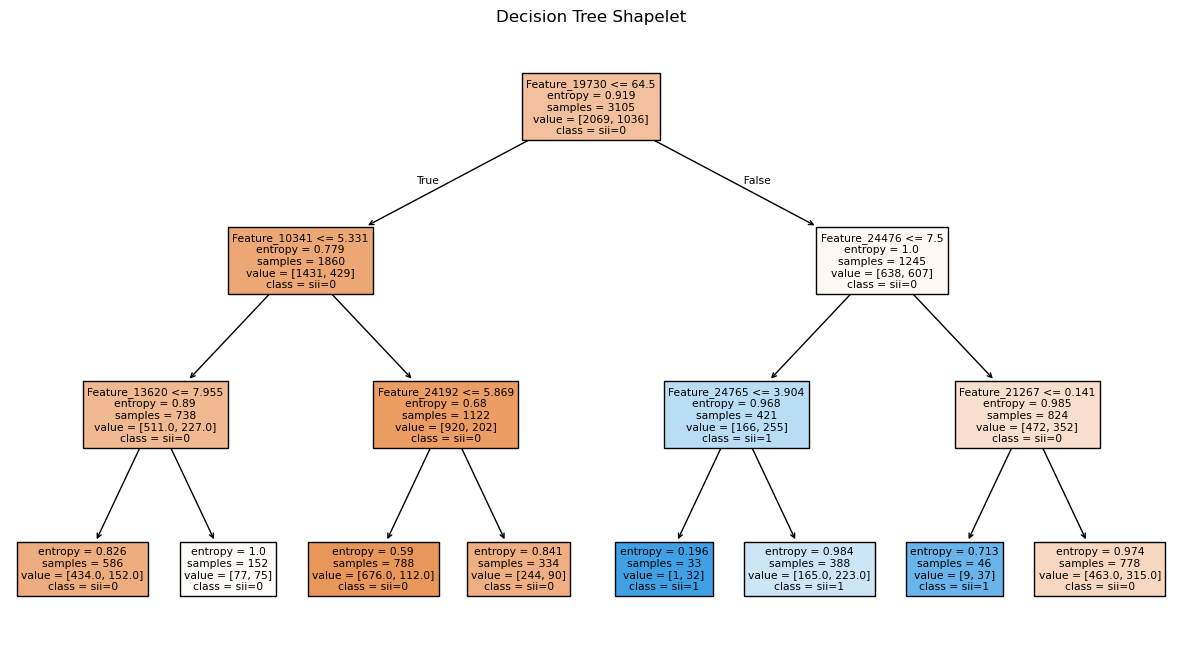

--- TOP 3 SHAPELETS PIÙ IMPORTANTI ---

Top 1 feature discriminante: n° 19730 (Importanza: 0.5429)
 -> Associata allo shapelet 6576, utilizzando la metrica: Frequenza (Occurrence)

Top 2 feature discriminante: n° 10341 (Importanza: 0.0991)
 -> Associata allo shapelet 3447, utilizzando la metrica: Distanza (minima)

Top 3 feature discriminante: n° 24476 (Importanza: 0.0882)
 -> Associata allo shapelet 8158, utilizzando la metrica: Frequenza (Occurrence)



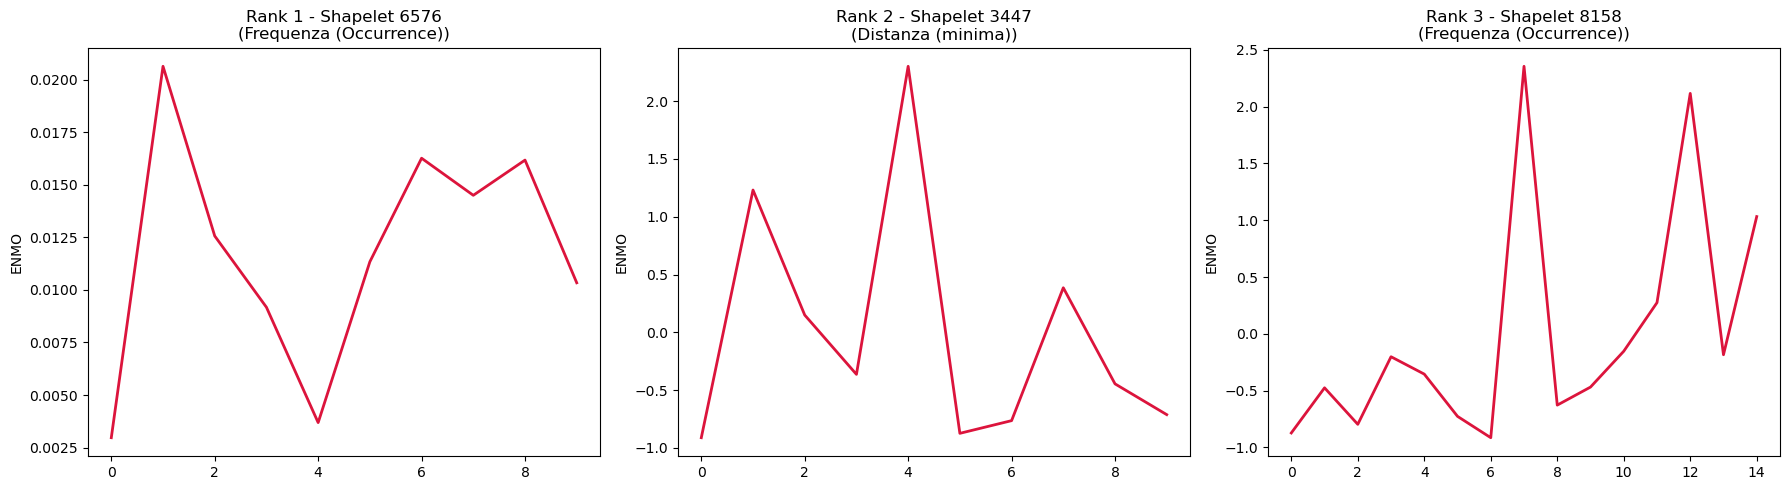

"\nI grafici in alto mostrano i 3 shapelet che l'albero ha ritenuto più importanti in base alla feature importance.\nPer ciascuno di essi, il resto della divisione intera ci indica quale delle 3 feature di quello shapelet ha usato:\nResto 0 = Distanza (QUANTO la serie temporale somiglia allo shapelet)\nResto 1 = Posizione Temporale/Argmin (QUANDO si presenta lo shapelet)\nResto 2 = Frequenza/Occurrence (QUANTE VOLTE si presenta lo shapelet)\nIn questo modo possiamo capire non solo quale forma (movimento) conta, ma ANCHE l'aspetto più discriminante ad essa legato.\n"

In [8]:
# Estrazione dei 3 Shapelet più importanti
best_dt = clf._estimator

plt.figure(figsize=(15, 8))
plot_tree(best_dt, filled=True, 
          feature_names=[f"Feature_{i}" for i in range(best_dt.n_features_in_)],
          class_names=["sii=0", "sii=1"])
plt.title("Decision Tree Shapelet")
plt.show()

import numpy as np

try:
    # Prendi le top 3 features per importanza
    importances = best_dt.feature_importances_
    top_3_features_idx = np.argsort(importances)[::-1][:3]
    
    num_shapelets = clf._transformer.shapelets_[0].shape[0]
    features_per_shapelet = best_dt.n_features_in_ // num_shapelets
    
    plt.figure(figsize=(18, 5))
    
    shapelets_fase_b = []
    
    print("--- TOP 3 SHAPELETS PIÙ IMPORTANTI ---\n")
    
    for i, feature_idx in enumerate(top_3_features_idx):
        shapelet_array_idx = feature_idx // features_per_shapelet
        feature_type_remainder = feature_idx % features_per_shapelet
        
        # Tipo di feature estratta dal RDST
        if feature_type_remainder == 0:
            feature_type_name = "Distanza (minima)"
        elif feature_type_remainder == 1:
            feature_type_name = "Posizione Temporale (Argmin)"
        elif feature_type_remainder == 2:
            feature_type_name = "Frequenza (Occurrence)"
        else:
            feature_type_name = "Sconosciuta"
            
        best_shapelet = clf._transformer.shapelets_[0][shapelet_array_idx][0]
        shapelets_fase_b.append(best_shapelet)
        
        plt.subplot(1, 3, i + 1)
        plt.plot(best_shapelet, color='crimson', linewidth=2)
        plt.title(f"Rank {i+1} - Shapelet {shapelet_array_idx}\n({feature_type_name})")
        plt.ylabel("ENMO")
        
        print(f"Top {i+1} feature discriminante: n° {feature_idx} (Importanza: {importances[feature_idx]:.4f})")
        print(f" -> Associata allo shapelet {shapelet_array_idx}, utilizzando la metrica: {feature_type_name}\n")

    plt.tight_layout()
    plt.show()

except Exception as e:
    print("Non è stato possibile estrarre la forma grezza per il plot. Errore:", e)
    shapelets_fase_b = []

# In RDST, l'estrattore genera tipicamente 3 feature per ogni shapelet (es. minima distanza, posizione, ecc.)
# L'indice reale dello shapelet nell'array è quindi feature_idx // 3

'''
I grafici in alto mostrano i 3 shapelet che l'albero ha ritenuto più importanti in base alla feature importance.
Per ciascuno di essi, il resto della divisione intera ci indica quale delle 3 feature di quello shapelet ha usato:
Resto 0 = Distanza (QUANTO la serie temporale somiglia allo shapelet)
Resto 1 = Posizione Temporale/Argmin (QUANDO si presenta lo shapelet)
Resto 2 = Frequenza/Occurrence (QUANTE VOLTE si presenta lo shapelet)
In questo modo possiamo capire non solo quale forma (movimento) conta, ma ANCHE l'aspetto più discriminante ad essa legato.
'''


## Fase 3: Il Ponte d'Oro (Shapelets vs Motifs)
Confrontiamo la firma discriminatoria globale appena estratta (Shapelet) con la routine locale (Motif) e l'anomalia locale (Discord) dei nostri medoidi.

--- PHASE 3: Global vs Local Comparison ---


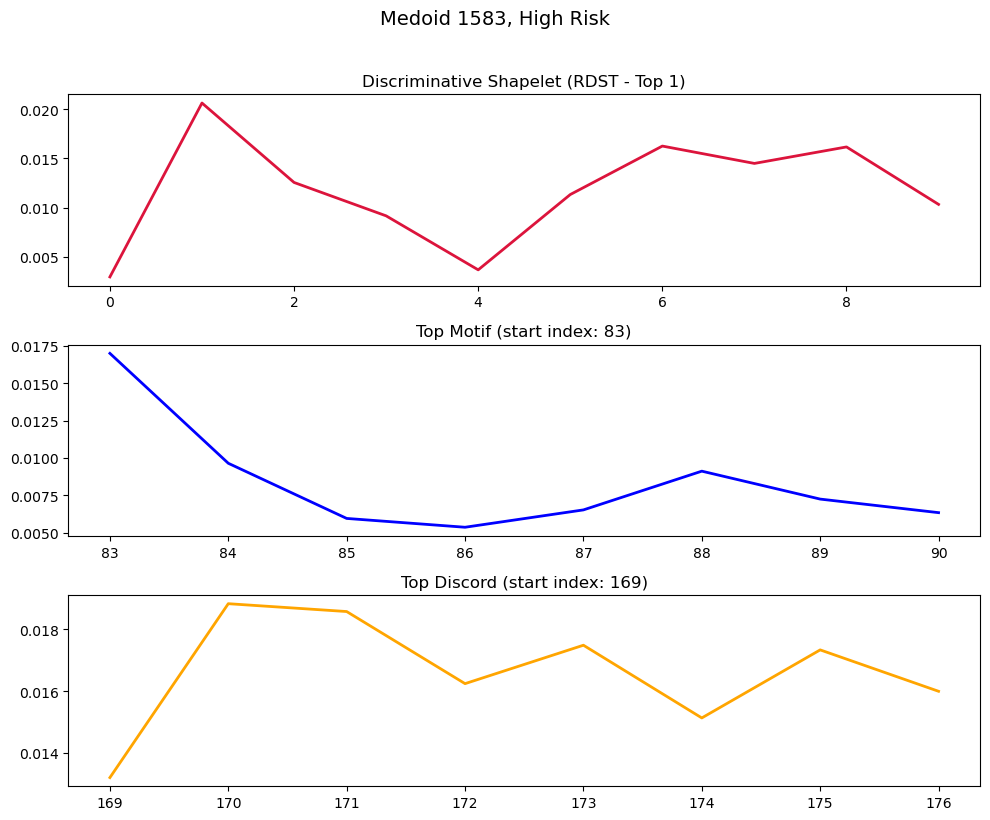

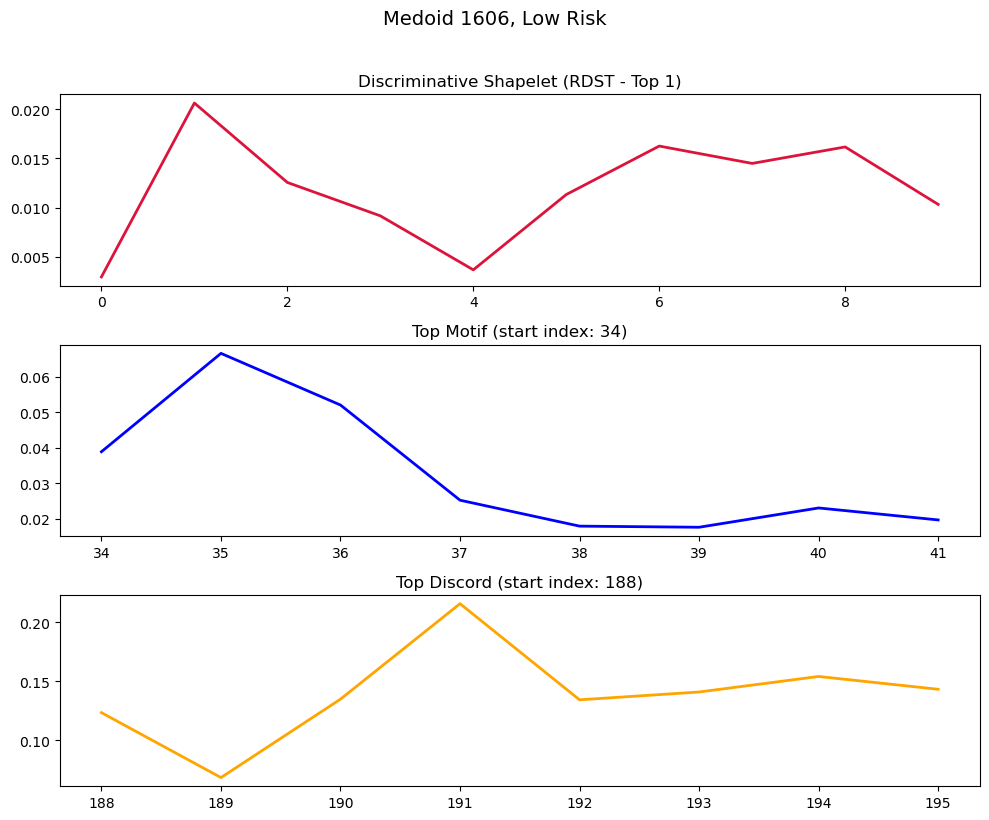

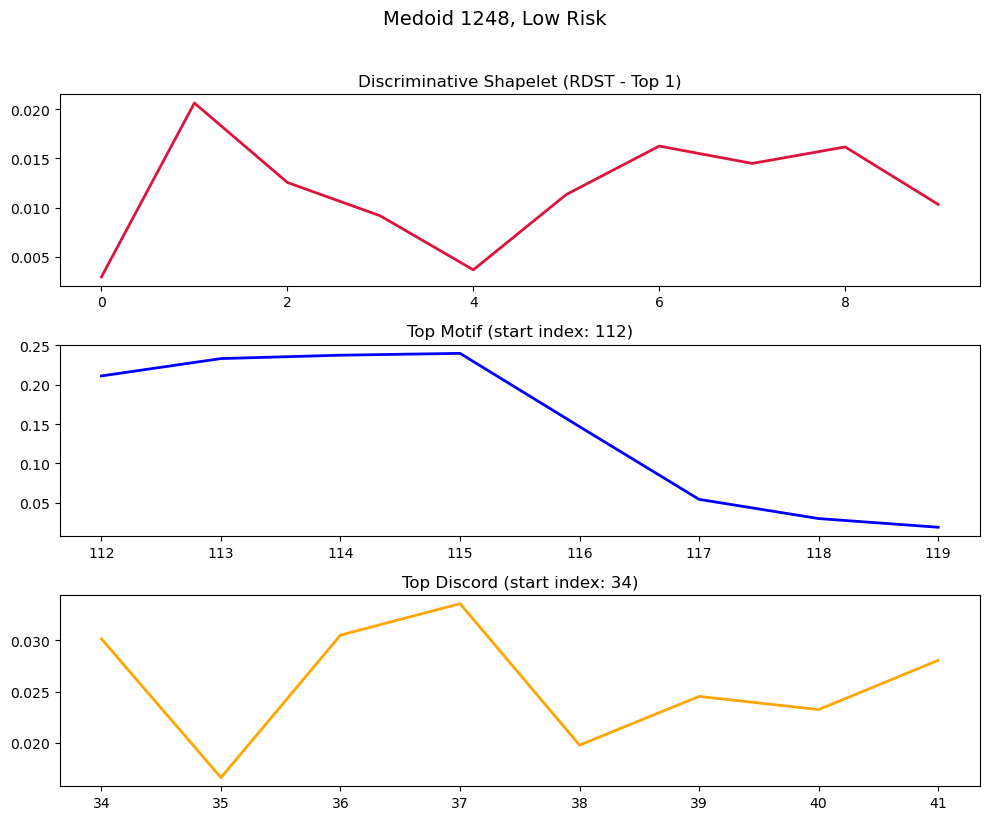

In [10]:
if 'shapelets_fase_b' in locals() and len(shapelets_fase_b) > 0:
    print(f"--- PHASE 3: Global vs Local Comparison ---")
    
    for idx in medoid_idx:
        ts_esempio = X[idx]
        label = "High Risk" if y[idx] == 1 else "Low Risk"
        
        mp = stumpy.stump(ts_esempio.astype(np.float64), m)
        motif_idx = mp[:, 0].argmin()
        discord_idx = mp[:, 0].argmax()
        
        top_motif = ts_esempio[motif_idx : motif_idx + m]
        top_discord = ts_esempio[discord_idx : discord_idx + m]
        
        fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=False)
        fig.suptitle(f"Medoid {idx}, {label}", fontsize=14, y=1.02)
        
        # Disegniamo lo Shapelet più significativo (indice 0)
        axs[0].plot(shapelets_fase_b[0], color='crimson', linewidth=2)
        axs[0].set_title("Discriminative Shapelet (RDST - Top 1)")
        
        axs[1].plot(range(motif_idx, motif_idx + m), top_motif, color='blue', linewidth=2)
        axs[1].set_title(f"Top Motif (start index: {motif_idx})")
        
        axs[2].plot(range(discord_idx, discord_idx + m), top_discord, color='orange', linewidth=2)
        axs[2].set_title(f"Top Discord (start index: {discord_idx})")
        
        plt.tight_layout()
        plt.show()
else:
    print("Unable to perform comparison.")


### Commento ai Risultati

La rimozione della standardizzazione istanza-per-istanza ha ripristinato il corretto significato fisico dei dati di accelerometria. In questo modo:
1. **L'intensità assoluta del movimento è preservata:** L'RDSTClassifier può ora identificare gli shapelet non solo in base alla *forma* relativa, ma sfruttando le naturali escursioni di ampiezza tra bambini sedentari e attivi.
2. **Correttezza metodologica per algoritmi geometrici:** Come richiesto, l'allineamento e il matching delle sottosequenze avvengono localmente (tramite Z-normalization intrinseca del Matrix Profile o della distanza euclidea su finestre limitate), evitando l'appiattimento distruttivo sull'intero tracciato.

Confrontando visivamente i pattern, notiamo se la firma globale del rischio patologico (lo Shapelet rosso) assuma una forma più vicina alla routine (Motif blu) del bambino, o a un evento anomalo/insolito (Discord arancione).